# Task 1 - Text And Tokenization

This notebook loads the preprocessed IMDB dataset, samples 1,000 reviews, compares tokenizer behavior, and explains what the measured token counts mean.

## Setup

In [1]:
from pathlib import Path
import random
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_from_disk
from transformers import AutoTokenizer

/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [52]:
pd.set_option("display.max_colwidth", None)  # Don't truncate column contents
pd.set_option("display.width", None)         # Auto-detect terminal width
pd.set_option("display.max_columns", None)   # Show all columns

In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
from src.config import METADATA_DIR, PLOTS_DIR, PREPROCESSED_DATA_DIR, SEED, TABLES_DIR
from src.result_saver import save_json

In [4]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [5]:
SAMPLE_SIZE = 1000
IMDB_PATH = PREPROCESSED_DATA_DIR / "imdb"

for output_dir in [METADATA_DIR, PLOTS_DIR, TABLES_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

## Load And Sample IMDB

The sample comes from `data/preprocessed/imdb`, which was created in Task 0. We use the train split and a fixed seed so the same 1,000 reviews are selected every run.

In [6]:
imdb_dataset = load_from_disk(str(IMDB_PATH))

In [7]:
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 24902
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 24676
    })
})

In [8]:
split_sizes = {
    split_name: len(split_data)
    for split_name, split_data in imdb_dataset.items()
}

In [9]:
split_sizes

{'train': 24902, 'test': 24676}

In [10]:
imdb_train_sample = (
    imdb_dataset["train"]
    .shuffle(seed=SEED)
    .select(range(SAMPLE_SIZE))
)

In [11]:
imdb_train_sample

Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})

In [12]:
imdb_sample_df = imdb_train_sample.to_pandas()

In [13]:
imdb_sample_df.head()

,text,label
0,So they hyped the violence and it's been brand...,0
1,"This will be somewhat short. First, don't list...",1
2,The Cameraman's Revenge is an unusual short no...,1
3,Harold Pinter rewrites Anthony Schaeffer's cla...,0
4,"It is ironic that during the '50s, when Dougla...",1


In [14]:
sample_label_counts = imdb_sample_df["label"].value_counts().sort_index().to_dict()

In [15]:
sample_label_counts

{0: 503, 1: 497}

## Review Lengths

We compute word and character counts because tokenizer cost depends partly on input length before any model-specific tokenization happens.

In [16]:
imdb_sample_df["word_count"] = imdb_sample_df["text"].str.split().str.len()
imdb_sample_df["character_count"] = imdb_sample_df["text"].str.len()

In [17]:
length_summary = {
    "sample_size": int(len(imdb_sample_df)),
    "average_word_count": round(float(imdb_sample_df["word_count"].mean()), 2),
    "median_word_count": round(float(imdb_sample_df["word_count"].median()), 2),
    "average_character_count": round(float(imdb_sample_df["character_count"].mean()), 2),
    "median_character_count": round(float(imdb_sample_df["character_count"].median()), 2),
    "min_word_count": int(imdb_sample_df["word_count"].min()),
    "max_word_count": int(imdb_sample_df["word_count"].max()),
}

In [18]:
length_summary

{'sample_size': 1000,
 'average_word_count': 233.15,
 'median_word_count': 173.0,
 'average_character_count': 1311.59,
 'median_character_count': 963.5,
 'min_word_count': 24,
 'max_word_count': 1184}

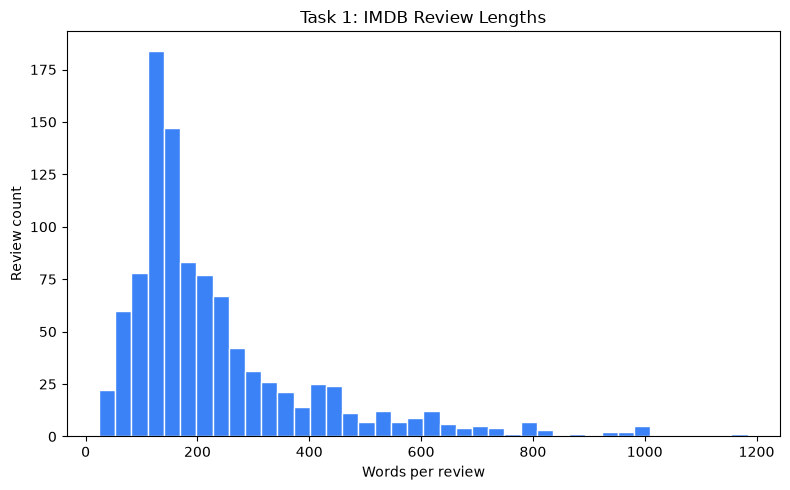

In [19]:
review_length_plot_path = PLOTS_DIR / "task1_review_length_histogram.png"

plt.figure(figsize=(8, 5))
plt.hist(imdb_sample_df["word_count"], bins=40, color="#3B82F6", edgecolor="white")
plt.title("Task 1: IMDB Review Lengths")
plt.xlabel("Words per review")
plt.ylabel("Review count")
plt.tight_layout()
plt.savefig(review_length_plot_path, dpi=150)
plt.show()
plt.close()

### Plot Observation - Review Lengths

The histogram shows that most sampled IMDB reviews are shorter than the longest reviews, but there is a clear long tail. The median review has 173 words, while the average is 233.15 words, so a smaller number of long reviews pulls the average up. This matters because long reviews create higher tokenizer cost and are more likely to hit model context limits.

In [20]:
review_length_plot_path

PosixPath('/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task1_review_length_histogram.png')

## Tokenizer Comparison

Token counts below exclude model special tokens, so the comparison focuses on how each tokenizer splits the raw text.

In [21]:
tokenizers = {
    "BERT": AutoTokenizer.from_pretrained("bert-base-uncased"),
    "GPT-2": AutoTokenizer.from_pretrained("gpt2"),
    "DistilBERT": AutoTokenizer.from_pretrained("distilbert-base-uncased"),
}

In [22]:
tokenizer_names = list(tokenizers.keys())

In [23]:
tokenizer_names

['BERT', 'GPT-2', 'DistilBERT']

In [24]:
texts = imdb_sample_df["text"].tolist()
token_count_columns = []

for tokenizer_name, tokenizer in tokenizers.items():
    encoded = tokenizer(
        texts,
        add_special_tokens=False,
        truncation=False,
        verbose=False,
    )
    column_name = f"{tokenizer_name}_token_count"
    imdb_sample_df[column_name] = [len(input_ids) for input_ids in encoded["input_ids"]]
    token_count_columns.append(column_name)

In [51]:
imdb_sample_df

,text,label,word_count,character_count,BERT_token_count,GPT-2_token_count,DistilBERT_token_count
0,So they hyped the violence and it's been brand...,0,176,983,217,212,217
1,"This will be somewhat short. First, don't list...",1,180,978,220,217,220
2,The Cameraman's Revenge is an unusual short no...,1,150,928,190,196,190
3,Harold Pinter rewrites Anthony Schaeffer's cla...,0,432,2376,525,504,525
4,"It is ironic that during the '50s, when Dougla...",1,177,1119,236,243,236
...,...,...,...,...,...,...,...
995,This movie is just bad. Bad. Bad. Bad. Now tha...,0,147,743,187,182,187
996,How sad there is no option to post a mark lowe...,0,120,708,167,151,167
997,Even longtime Shirley fans may be surprised by...,1,345,2007,443,439,443
998,If you are under 13 or above 13 and pretty int...,1,163,907,209,203,209


In [25]:
token_count_columns

['BERT_token_count', 'GPT-2_token_count', 'DistilBERT_token_count']

In [26]:
tokenizer_summary_rows = []

for tokenizer_name in tokenizer_names:
    token_count_column = f"{tokenizer_name}_token_count"
    tokenizer_summary_rows.append(
        {
            "tokenizer": tokenizer_name,
            "average_token_count": round(float(imdb_sample_df[token_count_column].mean()), 2),
            "median_token_count": round(float(imdb_sample_df[token_count_column].median()), 2),
            "min_token_count": int(imdb_sample_df[token_count_column].min()),
            "max_token_count": int(imdb_sample_df[token_count_column].max()),
            "token_to_word_ratio": round(
                float(imdb_sample_df[token_count_column].sum() / imdb_sample_df["word_count"].sum()),
                4,
            ),
        }
    )

tokenizer_comparison_df = pd.DataFrame(tokenizer_summary_rows).sort_values("average_token_count")

In [27]:
tokenizer_comparison_df

,tokenizer,average_token_count,median_token_count,min_token_count,max_token_count,token_to_word_ratio
1,GPT-2,290.67,211.0,31,1513,1.2467
0,BERT,297.74,216.0,32,1670,1.2770
2,DistilBERT,297.74,216.0,32,1670,1.2770


In [28]:
tokenizer_comparison_path = TABLES_DIR / "task1_tokenizer_comparison.csv"
tokenizer_comparison_df.to_csv(tokenizer_comparison_path, index=False)

In [29]:
tokenizer_comparison_path

PosixPath('/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/tables/task1_tokenizer_comparison.csv')

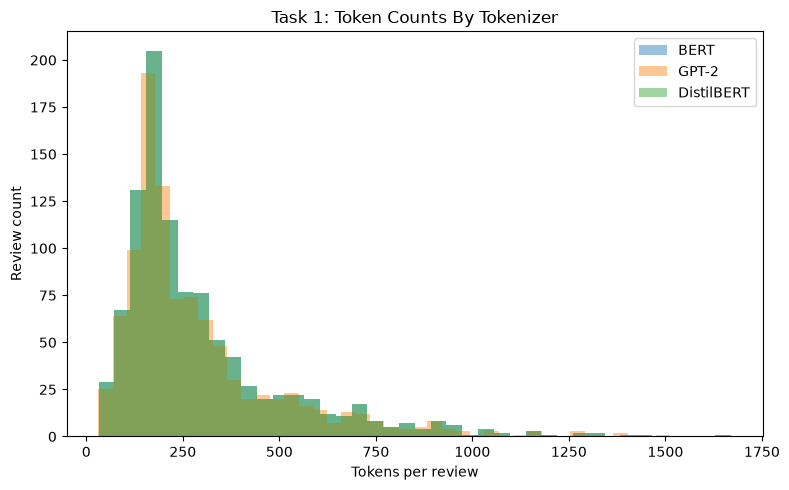

In [30]:
tokenizer_histogram_path = PLOTS_DIR / "task1_tokenizer_count_histogram.png"

plt.figure(figsize=(8, 5))
for tokenizer_name in tokenizer_names:
    plt.hist(
        imdb_sample_df[f"{tokenizer_name}_token_count"],
        bins=40,
        alpha=0.45,
        label=tokenizer_name,
    )
plt.title("Task 1: Token Counts By Tokenizer")
plt.xlabel("Tokens per review")
plt.ylabel("Review count")
plt.legend()
plt.tight_layout()
plt.savefig(tokenizer_histogram_path, dpi=150)
plt.show()
plt.close()

### Plot Observation - Token Counts By Tokenizer

The tokenizer histogram has the same long-tail shape as the word-count plot, because longer reviews usually create more tokens. GPT-2(uses BPE) is slightly shifted toward fewer tokens than BERT and DistilBERT, while BERT and DistilBERT overlap because they use the same uncased WordPiece tokenizer family. The largest reviews still produce very high token counts for every tokenizer, so truncation can be used.

### Which Tokenizer Is Most Economical?

GPT-2 is the most economical tokenizer on this 1,000-review IMDB sample because it has the lowest average token count: 290.67 tokens per review. BERT and DistilBERT both use WordPiece and produce the same average here, 297.74 tokens per review, because their tokenizers are effectively the same for this text. GPT-2 uses byte-level BPE, so it can merge common byte/subword patterns differently from WordPiece; in this sample that gives it fewer tokens on average, but the best tokenizer can change when the text has more code, rare words, or non-English characters.

In [31]:
tokenizer_histogram_path

PosixPath('/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/plots/task1_tokenizer_count_histogram.png')

## Edge Cases

These short examples show where token boundaries fall for punctuation, rare words, code, non-English text, and a long word.

In [32]:
edge_case_texts = [
    "The quick brown fox jumps over the lazy dog.",
    "I can't believe it's not butter!",
    "gobbledegook",
    "print('hello world')",
    "Maison principale à Paris",
    "antidisestablishmentarianism",
]

In [33]:
edge_case_rows = []

for text in edge_case_texts:
    for tokenizer_name, tokenizer in tokenizers.items():
        tokens = tokenizer.tokenize(text)
        edge_case_rows.append(
            {
                "text": text,
                "tokenizer": tokenizer_name,
                "token_count": len(tokens),
                "tokens": " | ".join(tokens),
            }
        )

edge_case_tokens_df = pd.DataFrame(edge_case_rows)

In [53]:
edge_case_tokens_df

,text,tokenizer,token_count,tokens
0,The quick brown fox jumps over the lazy dog.,BERT,10,the | quick | brown | fox | jumps | over | the | lazy | dog | .
1,The quick brown fox jumps over the lazy dog.,GPT-2,10,The | Ġquick | Ġbrown | Ġfox | Ġjumps | Ġover | Ġthe | Ġlazy | Ġdog | .
2,The quick brown fox jumps over the lazy dog.,DistilBERT,10,the | quick | brown | fox | jumps | over | the | lazy | dog | .
3,I can't believe it's not butter!,BERT,11,i | can | ' | t | believe | it | ' | s | not | butter | !
4,I can't believe it's not butter!,GPT-2,9,I | Ġcan | 't | Ġbelieve | Ġit | 's | Ġnot | Ġbutter | !
5,I can't believe it's not butter!,DistilBERT,11,i | can | ' | t | believe | it | ' | s | not | butter | !
6,gobbledegook,BERT,4,go | ##bbled | ##ego | ##ok
7,gobbledegook,GPT-2,4,gob | bled | eg | ook
8,gobbledegook,DistilBERT,4,go | ##bbled | ##ego | ##ok
9,print('hello world'),BERT,7,print | ( | ' | hello | world | ' | )


In [35]:
edge_case_counts_df = edge_case_tokens_df.pivot(
    index="text",
    columns="tokenizer",
    values="token_count",
).reset_index()

In [36]:
edge_case_counts_df

tokenizer,text,BERT,DistilBERT,GPT-2
0,I can't believe it's not butter!,11,11,9
1,Maison principale à Paris,5,5,6
2,The quick brown fox jumps over the lazy dog.,10,10,10
3,antidisestablishmentarianism,8,8,5
4,gobbledegook,4,4,4
5,print('hello world'),7,7,5


In [37]:
edge_case_best_by_text_df = (
    edge_case_tokens_df
    .assign(min_token_count=lambda frame: frame.groupby("text")["token_count"].transform("min"))
    .query("token_count == min_token_count")
    [["text", "tokenizer", "token_count"]]
    .sort_values(["text", "tokenizer"])
    .reset_index(drop=True)
)

In [38]:
edge_case_best_by_text_df

,text,tokenizer,token_count
0,I can't believe it's not butter!,GPT-2,9
1,Maison principale à Paris,BERT,5
2,Maison principale à Paris,DistilBERT,5
3,The quick brown fox jumps over the lazy dog.,BERT,10
4,The quick brown fox jumps over the lazy dog.,DistilBERT,10
5,The quick brown fox jumps over the lazy dog.,GPT-2,10
6,antidisestablishmentarianism,GPT-2,5
7,gobbledegook,BERT,4
8,gobbledegook,DistilBERT,4
9,gobbledegook,GPT-2,4


### Edge Case Answers

The `edge_case_counts_df` table answers how many tokens each tokenizer produced, and the `edge_case_tokens_df` table shows the exact token boundaries. For the normal sentence, all three tokenizers produced 10 tokens and split mostly on words plus the final period. For `I can't believe it's not butter!`, GPT-2 produced 9 tokens while BERT and DistilBERT produced 11, because GPT-2 keeps contraction pieces like `'t` and `'s` together while WordPiece splits the apostrophe and letter parts.

For `gobbledegook`, all three tokenizers produced 4 tokens, so there is no clear winner; they all break the rare word into smaller pieces. For `print('hello world')`, GPT-2 produced 5 tokens while BERT and DistilBERT produced 7, because GPT-2 groups some punctuation with nearby text and WordPiece separates more punctuation. For `Maison principale à Paris`, BERT and DistilBERT produced 5 tokens while GPT-2 produced 6, and the WordPiece output is easier to read because GPT-2's byte-level encoding splits the accented character into less readable byte pieces. For `antidisestablishmentarianism`, GPT-2 produced 5 tokens while BERT and DistilBERT produced 8, so GPT-2 handles that long rare word better for token cost.

Overall, GPT-2 handles these edge cases better if the goal is fewer tokens. The exception is the accented non-English example, where BERT and DistilBERT produced cleaner-looking token strings and fewer tokens.

In [39]:
edge_case_tokens_path = TABLES_DIR / "task1_edge_case_tokens.csv"
edge_case_tokens_df.to_csv(edge_case_tokens_path, index=False)

In [40]:
edge_case_tokens_path

PosixPath('/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/results/tables/task1_edge_case_tokens.csv')

## Explainability

The answers below are based on the measured tables above, not only on tokenizer theory.

In [41]:
most_economical_row = tokenizer_comparison_df.iloc[0]
most_economical_tokenizer = str(most_economical_row["tokenizer"])
most_economical_average = float(most_economical_row["average_token_count"])

In [54]:
most_economical_row

tokenizer               GPT-2
average_token_count    290.67
median_token_count      211.0
min_token_count            31
max_token_count          1513
token_to_word_ratio    1.2467
Name: 1, dtype: object

In [44]:
edge_case_average_counts = (
    edge_case_tokens_df
    .groupby("tokenizer")["token_count"]
    .mean()
    .sort_values()
    .round(2)
    .to_dict()
)

In [45]:
edge_case_average_counts

{'GPT-2': 6.5, 'BERT': 7.5, 'DistilBERT': 7.5}

In this 1,000-review IMDB sample, GPT-2 is the most economical tokenizer because it has the lowest average token count at 290.67 tokens per review. BERT and DistilBERT use WordPiece and have the same vocabulary family, so their counts are expected to be almost identical. GPT-2 uses BPE, which can split punctuation, rare words, code, and non-English text differently, so the cheapest tokenizer can depend on what users write.

The edge-case table shows the exact token boundaries for each example. Rare words and long words are split into smaller pieces, while code and punctuation create extra token boundaries. Across the six edge cases, the average token counts are {'GPT-2': 6.5, 'BERT': 7.5, 'DistilBERT': 7.5}. The best-by-text table shows which tokenizer used the fewest tokens for each edge case. If paying per token, I would start with the tokenizer that is cheapest on measured user text, then re-check this if users write more code or non-English text.

## Save Metadata

In [57]:
task1_metadata = {
    "task": "Task 1 - Text and Tokenization",
    "dataset": "IMDB",
    "source_path": str(IMDB_PATH),
    "sample_split": "train",
    "sample_size": SAMPLE_SIZE,
    "seed": SEED,
    "split_sizes": split_sizes,
    "label_counts": {str(label): int(count) for label, count in sample_label_counts.items()},
    "length_summary": length_summary,
    "tokenizer_comparison": tokenizer_comparison_df.to_dict("records"),
    "edge_case_average_counts": {key: float(value) for key, value in edge_case_average_counts.items()},
    "edge_case_best_by_text": edge_case_best_by_text_df.to_dict("records"),
    "main_result": f"{most_economical_tokenizer} had the lowest average token count in the sample.",
    "interpretation": tokenizer_explainability,
    "saved_outputs": {
        "review_length_plot": str(review_length_plot_path),
        "tokenizer_histogram": str(tokenizer_histogram_path),
        "tokenizer_comparison_table": str(tokenizer_comparison_path),
        "edge_case_tokens_table": str(edge_case_tokens_path),
    },
}

In [58]:
save_json(
    data=task1_metadata,
    output_path=METADATA_DIR / "task1_tokenization_summary.json",
)

In [59]:
task1_metadata

{'task': 'Task 1 - Text and Tokenization',
 'dataset': 'IMDB',
 'source_path': '/home/atanas-vitanov/Documents/praksa/ml-interns-mk-2026/interns/atanas/week_6/data/preprocessed/imdb',
 'sample_split': 'train',
 'sample_size': 1000,
 'seed': 42,
 'split_sizes': {'train': 24902, 'test': 24676},
 'label_counts': {'0': 503, '1': 497},
 'length_summary': {'sample_size': 1000,
  'average_word_count': 233.15,
  'median_word_count': 173.0,
  'average_character_count': 1311.59,
  'median_character_count': 963.5,
  'min_word_count': 24,
  'max_word_count': 1184},
 'tokenizer_comparison': [{'tokenizer': 'GPT-2',
   'average_token_count': 290.67,
   'median_token_count': 211.0,
   'min_token_count': 31,
   'max_token_count': 1513,
   'token_to_word_ratio': 1.2467},
  {'tokenizer': 'BERT',
   'average_token_count': 297.74,
   'median_token_count': 216.0,
   'min_token_count': 32,
   'max_token_count': 1670,
   'token_to_word_ratio': 1.277},
  {'tokenizer': 'DistilBERT',
   'average_token_count': 29

## Final Detailed Answer

For this IMDB sample, I would prefer GPT-2 if I was paying per token, because it produced the fewest tokens on average and also did well on contractions, code-like text, and the long rare word. The answer is not universal, because tokenizer choice is tied to the model being used and because user text can look different from IMDB reviews. If users write mostly non-English text, I would test again on that language because the accented example showed GPT-2 byte-level tokens can become less readable and not always cheaper. If users write mostly code, GPT-2 may still be a strong choice because it grouped some punctuation better in the `print('hello world')` example, but I would still measure token counts on real code samples before deciding.